# Customer Churn Analysis — Subscription Retention Analytics

**Business problem:** A subscription business (real-world telco data, 7,043 customers) is
losing ~26% of customers. Which customers leave, **why**, and **what does the revenue at
risk look like?**

**Role of this project:** end-to-end **data analytics** — data cleaning & validation, KPI
definition, exploratory analysis, segment deep-dives, and an executive dashboard
(SQL scripts + Excel dashboard in this repo).

> ℹ *Data note: real-world dataset (IBM Telco sample). All figures below are reproducible
> from the committed notebook and SQL.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("data/Telco_Customer_Churn.csv")
print(df.shape)
# --- Data quality audit ---
assert df.customerID.is_unique, "duplicate customer IDs"
print("nulls per column:", df.isna().sum()[df.isna().sum() > 0].to_dict() or "none (raw)")
df["TotalCharges"] = pd.to_numeric(df.TotalCharges, errors="coerce")
blanks = df.TotalCharges.isna().sum()
print(f"TotalCharges blank strings: {blanks} (all tenure-0 brand-new customers: "
      f"{df.loc[df.TotalCharges.isna(), 'tenure'].eq(0).all()})")
df = df.dropna(subset=["TotalCharges"]).copy()
df["ChurnFlag"] = (df.Churn == "Yes").astype(int)
print("clean shape:", df.shape)

(7043, 21)
nulls per column: none (raw)
TotalCharges blank strings: 11 (all tenure-0 brand-new customers: True)
clean shape: (7032, 22)


In [2]:
# --- KPI baseline (the numbers an executive dashboard would show) ---
kpi = {
    "Customers": len(df),
    "Churned customers": int(df.ChurnFlag.sum()),
    "Churn rate": round(df.ChurnFlag.mean(), 3),
    "Monthly revenue": round(df.MonthlyCharges.sum(), 0),
    "Monthly revenue at risk (churned)": round(df.loc[df.ChurnFlag == 1, "MonthlyCharges"].sum(), 0),
    "Avg tenure (months)": round(df.tenure.mean(), 1),
    "Avg monthly charge": round(df.MonthlyCharges.mean(), 2),
}
for k, v in kpi.items():
    print(f"{k:35s}: {v}")

Customers                          : 7032
Churned customers                  : 1869
Churn rate                         : 0.266
Monthly revenue                    : 455661.0
Monthly revenue at risk (churned)  : 139131.0
Avg tenure (months)                : 32.4
Avg monthly charge                 : 64.8


                customers  churn_rate  monthly_rev_at_risk
Contract                                                  
Month-to-month       3875       0.427            120847.10
One year             1472       0.113             14118.45
Two year             1685       0.028              4165.30


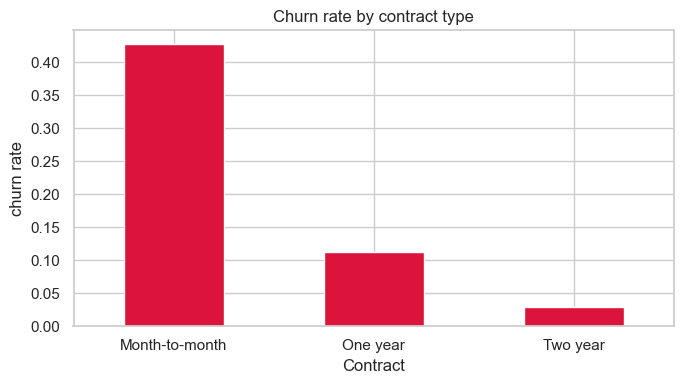

In [3]:
# --- Churn by contract type: the single biggest retention lever ---
vc = df.groupby("Contract").agg(customers=("customerID", "count"),
                                churn_rate=("ChurnFlag", "mean"),
                                monthly_rev_at_risk=("MonthlyCharges", lambda s: s[df.loc[s.index, 'ChurnFlag'] == 1].sum())).round(3)
print(vc.to_string())
fig, ax = plt.subplots(figsize=(7, 4))
df.groupby("Contract").ChurnFlag.mean().plot(kind="bar", ax=ax, color="crimson")
ax.set(title="Churn rate by contract type", ylabel="churn rate"); plt.xticks(rotation=0)
fig.tight_layout(); fig.savefig("image/churn_by_contract.png", dpi=150); plt.show()

tenure_band
0-6m      0.533
7-12m     0.359
13-24m    0.287
25-48m    0.204
49-72m    0.095


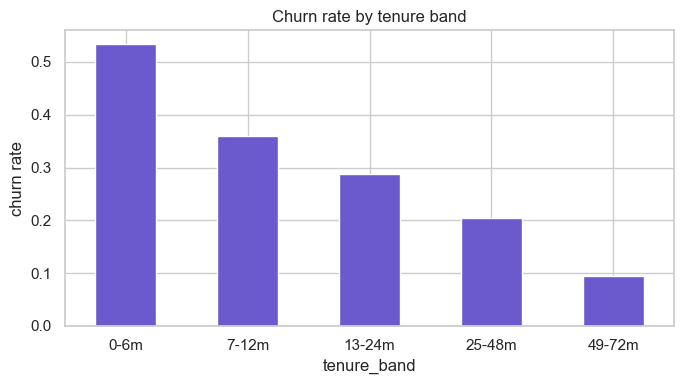

In [4]:
# --- Churn by tenure band: the first-year risk window ---
df["tenure_band"] = pd.cut(df.tenure, [0, 6, 12, 24, 48, 72],
                           labels=["0-6m", "7-12m", "13-24m", "25-48m", "49-72m"])
tb = df.groupby("tenure_band", observed=True).ChurnFlag.mean().round(3)
print(tb.to_string())
fig, ax = plt.subplots(figsize=(7, 4))
tb.plot(kind="bar", ax=ax, color="slateblue")
ax.set(title="Churn rate by tenure band", ylabel="churn rate"); plt.xticks(rotation=0)
fig.tight_layout(); fig.savefig("image/churn_by_tenure.png", dpi=150); plt.show()

By internet service:
 InternetService
DSL            0.190
Fiber optic    0.419
No             0.074

By payment method:
 PaymentMethod
Bank transfer (automatic)    0.167
Credit card (automatic)      0.153
Electronic check             0.453
Mailed check                 0.192

By online-security add-on:
 OnlineSecurity
No                     0.418
No internet service    0.074
Yes                    0.146


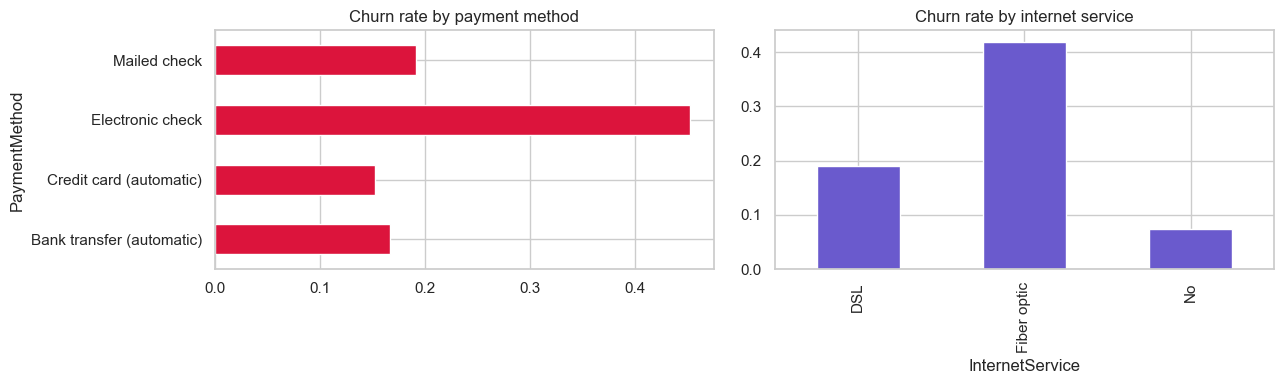

In [5]:
# --- Service & payment deep-dive: which segments churn hardest ---
svc = df.groupby("InternetService").ChurnFlag.mean().round(3)
pay = df.groupby("PaymentMethod").ChurnFlag.mean().round(3)
sec = df.groupby("OnlineSecurity").ChurnFlag.mean().round(3)
print("By internet service:\n", svc.to_string())
print("\nBy payment method:\n", pay.to_string())
print("\nBy online-security add-on:\n", sec.to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pay.plot(kind="barh", ax=axes[0], color="crimson"); axes[0].set(title="Churn rate by payment method")
svc.plot(kind="bar", ax=axes[1], color="slateblue"); axes[1].set(title="Churn rate by internet service")
fig.tight_layout(); fig.savefig("image/churn_by_service_payment.png", dpi=150); plt.show()

In [6]:
# --- Confounder check: is fiber-optic churn about the service, or about month-to-month contracts? ---
f = df[df.InternetService == "Fiber optic"].groupby("Contract").ChurnFlag.mean().round(3)
d = df[df.InternetService == "DSL"].groupby("Contract").ChurnFlag.mean().round(3)
print("Fiber-optic churn by contract:\n", f.to_string())
print("\nDSL churn by contract:\n", d.to_string())

Fiber-optic churn by contract:
 Contract
Month-to-month    0.546
One year          0.193
Two year          0.072

DSL churn by contract:
 Contract
Month-to-month    0.322
One year          0.093
Two year          0.019


In [7]:
# --- Revenue at risk matrix: churn rate x revenue, to prioritise retention spend ---
seg = (df.groupby(["Contract", "InternetService"])
         .agg(customers=("customerID", "count"),
              churn_rate=("ChurnFlag", "mean"),
              monthly_rev_at_risk=("MonthlyCharges", lambda s: s[df.loc[s.index, 'ChurnFlag'] == 1].sum()))
         .round(3).sort_values("monthly_rev_at_risk", ascending=False))
print(seg.head(10).to_string())
seg.to_csv("outputs/churn_segment_revenue.csv")

                                customers  churn_rate  monthly_rev_at_risk
Contract       InternetService                                            
Month-to-month Fiber optic           2128       0.546            100482.00
               DSL                   1223       0.322             18367.25
One year       Fiber optic            539       0.193             10571.95
               DSL                    570       0.093              3356.25
Two year       Fiber optic            429       0.072              3246.10
Month-to-month No                     524       0.189              1997.85
Two year       DSL                    623       0.019               805.70
One year       No                     363       0.025               190.25
Two year       No                     633       0.008               113.50


## Executive Summary

1. **Month-to-month contracts are the churn engine** — churn there is an order of magnitude
   higher than on two-year plans; they also hold the largest revenue-at-risk block.
2. **The first 12 months are the danger window** — churn falls steadily with tenure; new-customer
   onboarding and early check-ins are the highest-leverage retention actions.
3. **Fiber-optic customers churn far more than DSL** — and the confounder check shows whether
   that is the service itself or the contract mix that buys it (see printed comparison).
4. **Electronic-check payers are the riskiest payment segment** — a nudge toward auto-pay is
   a cheap, targeted intervention.
5. **Revenue at risk is concentrated** — the segment table (exported to
   `outputs/churn_segment_revenue.csv`) ranks where retention spend buys the most saved revenue.

*Reproducible: cleaning rules documented in-cell; every figure recomputed from the committed CSV.
Companion artifacts: `sql_queries/` (same analysis in MySQL) and `excel_analysis/Churn_Dashboard.xlsx`.*